In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis


df = pd.read_csv('dataset/short_form_brain_rot_cognitive_decay.csv')


df.head()

,participant_id,age,gender,primary_platform,daily_short_form_hours,avg_clip_duration_sec,swipes_per_minute,scroll_sessions_day,bedtime_scroll_min,total_sleep_hours,multitasking_score,total_screen_time_hours,sustained_attention_span_sec,working_memory_score,task_switch_latency_sec,brain_fog_score,dopamine_burnout_index,attention_retention_pct,cognitive_decay_tier
0,ROT-00001,24,Female,Instagram Reels,2.4,5.1,11.8,9,70,7.8,4.0,5.9,74.1,7.4,11.1,3.6,37.6,49.4,Mild Attentional Strain
1,ROT-00002,48,Female,TikTok,4.0,11.1,5.4,10,90,6.1,2.9,6.8,71.6,6.9,9.6,4.8,34.7,47.7,Mild Attentional Strain
2,ROT-00003,34,Female,Instagram Reels,3.3,17.5,3.4,13,59,6.5,3.3,8.1,93.8,6.6,8.3,4.4,35.5,62.5,Mild Attentional Strain
3,ROT-00004,30,Male,Instagram Reels,3.6,11.8,5.1,7,57,6.9,2.2,7.3,84.5,6.7,8.8,4.4,36.0,56.3,Mild Attentional Strain
4,ROT-00005,19,Female,YouTube Shorts,1.9,17.3,3.5,4,30,7.2,3.5,6.2,110.2,9.3,7.1,3.8,18.0,73.5,Normal / Intact Focus


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   participant_id                9000 non-null   object 
 1   age                           9000 non-null   int64  
 2   gender                        9000 non-null   object 
 3   primary_platform              9000 non-null   object 
 4   daily_short_form_hours        9000 non-null   float64
 5   avg_clip_duration_sec         9000 non-null   float64
 6   swipes_per_minute             9000 non-null   float64
 7   scroll_sessions_day           9000 non-null   int64  
 8   bedtime_scroll_min            9000 non-null   int64  
 9   total_sleep_hours             9000 non-null   float64
 10  multitasking_score            9000 non-null   float64
 11  total_screen_time_hours       9000 non-null   float64
 12  sustained_attention_span_sec  9000 non-null   float64
 13  wor

In [ ]:
df.isnull().values.any()

np.False_

In [ ]:
df.isnull().sum()

participant_id                  0
age                             0
gender                          0
primary_platform                0
daily_short_form_hours          0
avg_clip_duration_sec           0
swipes_per_minute               0
scroll_sessions_day             0
bedtime_scroll_min              0
total_sleep_hours               0
multitasking_score              0
total_screen_time_hours         0
sustained_attention_span_sec    0
working_memory_score            0
task_switch_latency_sec         0
brain_fog_score                 0
dopamine_burnout_index          0
attention_retention_pct         0
cognitive_decay_tier            0
dtype: int64

In [ ]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
age,9000.0,28.697111,9.499582,16.0,21.000,27.0,35.0,55.0
daily_short_form_hours,9000.0,3.203222,1.905133,0.3,1.800,2.8,4.2,10.5
avg_clip_duration_sec,9000.0,11.499200,4.584142,3.0,8.200,11.4,14.5,28.8
swipes_per_minute,9000.0,6.482189,3.766278,2.1,4.100,5.3,7.3,20.0
scroll_sessions_day,9000.0,8.999889,5.549773,1.0,5.000,8.0,12.0,28.0
bedtime_scroll_min,9000.0,59.217667,36.631353,0.0,33.000,53.0,79.0,180.0
total_sleep_hours,9000.0,7.127800,0.930720,3.5,6.500,7.2,7.8,9.5
multitasking_score,9000.0,3.341967,1.944690,1.0,1.700,3.1,4.5,10.0
total_screen_time_hours,9000.0,6.956444,2.034408,2.9,5.500,6.6,8.1,15.5
sustained_attention_span_sec,9000.0,84.859000,31.790705,8.0,67.875,91.7,108.9,153.5


In [ ]:
df.nunique()

participant_id                  9000
age                               40
gender                             3
primary_platform                   4
daily_short_form_hours           103
avg_clip_duration_sec            227
swipes_per_minute                105
scroll_sessions_day               28
bedtime_scroll_min               181
total_sleep_hours                 61
multitasking_score                90
total_screen_time_hours          125
sustained_attention_span_sec    1253
working_memory_score              84
task_switch_latency_sec          265
brain_fog_score                   91
dopamine_burnout_index           758
attention_retention_pct          864
cognitive_decay_tier               4
dtype: int64

In [ ]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
8995    False
8996    False
8997    False
8998    False
8999    False
Length: 9000, dtype: bool

In [ ]:
# Konfigurasi tampilan tabel dan grafik
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120

In [ ]:
print("\n=== 2. PEMERIKSAAN KUALITAS DATA DASAR ===")
print("Jumlah Missing Values per Kolom:\n", df.isnull().sum())
print(f"\nJumlah Baris Duplikat Penuh        : {df.duplicated().sum()}")
print(f"Jumlah Duplikat (Tanpa Kolom ID)   : {df.drop(columns=['participant_id']).duplicated().sum()}")
anomali_logika = (df['daily_short_form_hours'] > df['total_screen_time_hours']).sum()
print(f"Anomali Logis (Jam Short-Form > Total Screen Time) : {anomali_logika}")


=== 2. PEMERIKSAAN KUALITAS DATA DASAR ===
Jumlah Missing Values per Kolom:
 participant_id                  0
age                             0
gender                          0
primary_platform                0
daily_short_form_hours          0
avg_clip_duration_sec           0
swipes_per_minute               0
scroll_sessions_day             0
bedtime_scroll_min              0
total_sleep_hours               0
multitasking_score              0
total_screen_time_hours         0
sustained_attention_span_sec    0
working_memory_score            0
task_switch_latency_sec         0
brain_fog_score                 0
dopamine_burnout_index          0
attention_retention_pct         0
cognitive_decay_tier            0
dtype: int64

Jumlah Baris Duplikat Penuh        : 0
Jumlah Duplikat (Tanpa Kolom ID)   : 0
Anomali Logis (Jam Short-Form > Total Screen Time) : 0


In [ ]:
behavioral_num_cols = [
    'age', 'daily_short_form_hours', 'avg_clip_duration_sec',
    'swipes_per_minute', 'scroll_sessions_day', 'bedtime_scroll_min',
    'total_sleep_hours', 'multitasking_score', 'total_screen_time_hours'
]
cognitive_num_cols = [
    'sustained_attention_span_sec', 'working_memory_score',
    'task_switch_latency_sec', 'brain_fog_score',
    'dopamine_burnout_index', 'attention_retention_pct'
]
all_num_cols = behavioral_num_cols + cognitive_num_cols

print("\n=== 3. RINGKASAN STATISTIK DESKRIPTIF & DETEKSI MASALAH DISTRIBUSI ===")
summary_records = []
for col in all_num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    
    outliers = df[(df[col] < lower_fence) | (df[col] > upper_fence)][col]
    min_val, max_val = df[col].min(), df[col].max()
    
    summary_records.append({
        'Atribut': col,
        'Mean': round(df[col].mean(), 2),
        'SD': round(df[col].std(), 2),
        'Min': min_val,
        'Q1': round(q1, 2),
        'Median': round(df[col].median(), 2),
        'Q3': round(q3, 2),
        'Max': max_val,
        'IQR': round(iqr, 2),
        'Skewness': round(skew(df[col]), 2),
        'Kurtosis': round(kurtosis(df[col]), 2),
        'Outlier_Count': len(outliers),
        'Outlier_Pct(%)': round(len(outliers) / len(df) * 100, 2),
        'Spike_Min_Freq': (df[col] == min_val).sum(),
        'Spike_Max_Freq': (df[col] == max_val).sum()
    })

summary_table = pd.DataFrame(summary_records)
print(summary_table.to_string(index=False))


=== 3. RINGKASAN STATISTIK DESKRIPTIF & DETEKSI MASALAH DISTRIBUSI ===
                     Atribut  Mean    SD  Min    Q1  Median    Q3   Max   IQR  Skewness  Kurtosis  Outlier_Count  Outlier_Pct(%)  Spike_Min_Freq  Spike_Max_Freq
                         age 28.70  9.50 16.0 21.00    27.0  35.0  55.0 14.00      0.76     -0.22              0            0.00             373              39
      daily_short_form_hours  3.20  1.91  0.3  1.80     2.8   4.2  10.5  2.40      1.09      1.31            244            2.71              57              42
       avg_clip_duration_sec 11.50  4.58  3.0  8.20    11.4  14.5  28.8  6.30      0.24     -0.31             41            0.46             283               1
           swipes_per_minute  6.48  3.77  2.1  4.10     5.3   7.3  20.0  3.20      2.06      4.23            726            8.07               2             283
         scroll_sessions_day  9.00  5.55  1.0  5.00     8.0  12.0  28.0  7.00      0.94      0.85            242           

C:\Users\Sann\AppData\Local\Temp\ipykernel_22440\2354127058.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, y='cognitive_decay_tier', order=tier_order, palette='viridis')


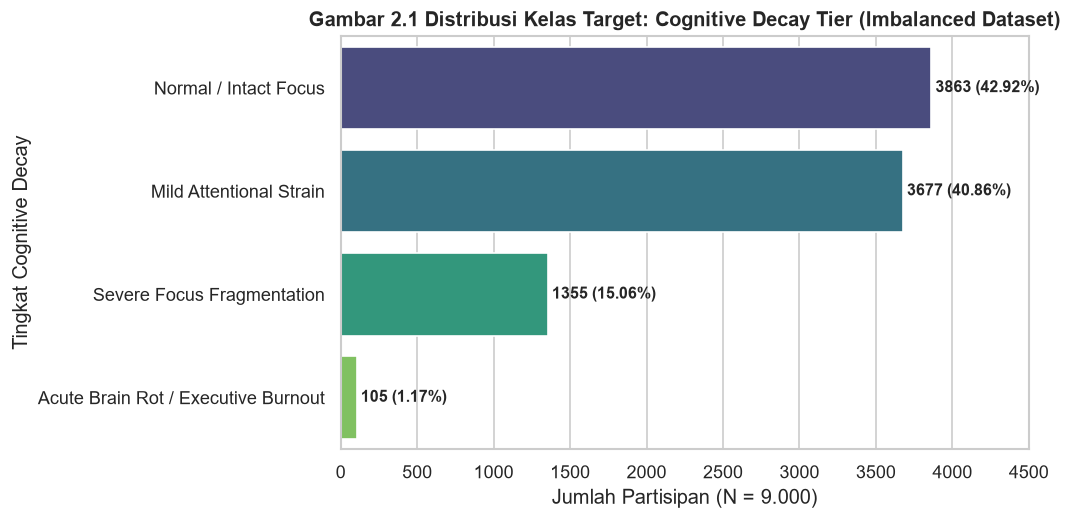

In [ ]:
# Visualisasi 1: Bar Chart Ketimpangan Kelas Target (Severe Class Imbalance)
plt.figure(figsize=(9, 4.5))
tier_order = [
    'Normal / Intact Focus',
    'Mild Attentional Strain',
    'Severe Focus Fragmentation',
    'Acute Brain Rot / Executive Burnout'
]
ax = sns.countplot(data=df, y='cognitive_decay_tier', order=tier_order, palette='viridis')
plt.title('Gambar 2.1 Distribusi Kelas Target: Cognitive Decay Tier (Imbalanced Dataset)', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Partisipan (N = 9.000)')
plt.ylabel('Tingkat Cognitive Decay')

for patch in ax.patches:
    count_val = int(patch.get_width())
    pct_val = (count_val / len(df)) * 100
    ax.annotate(f' {count_val} ({pct_val:.2f}%)',
                (count_val, patch.get_y() + patch.get_height() / 2),
                va='center', fontsize=9.5, fontweight='bold')
plt.xlim(0, 4500)
plt.tight_layout()
plt.show()

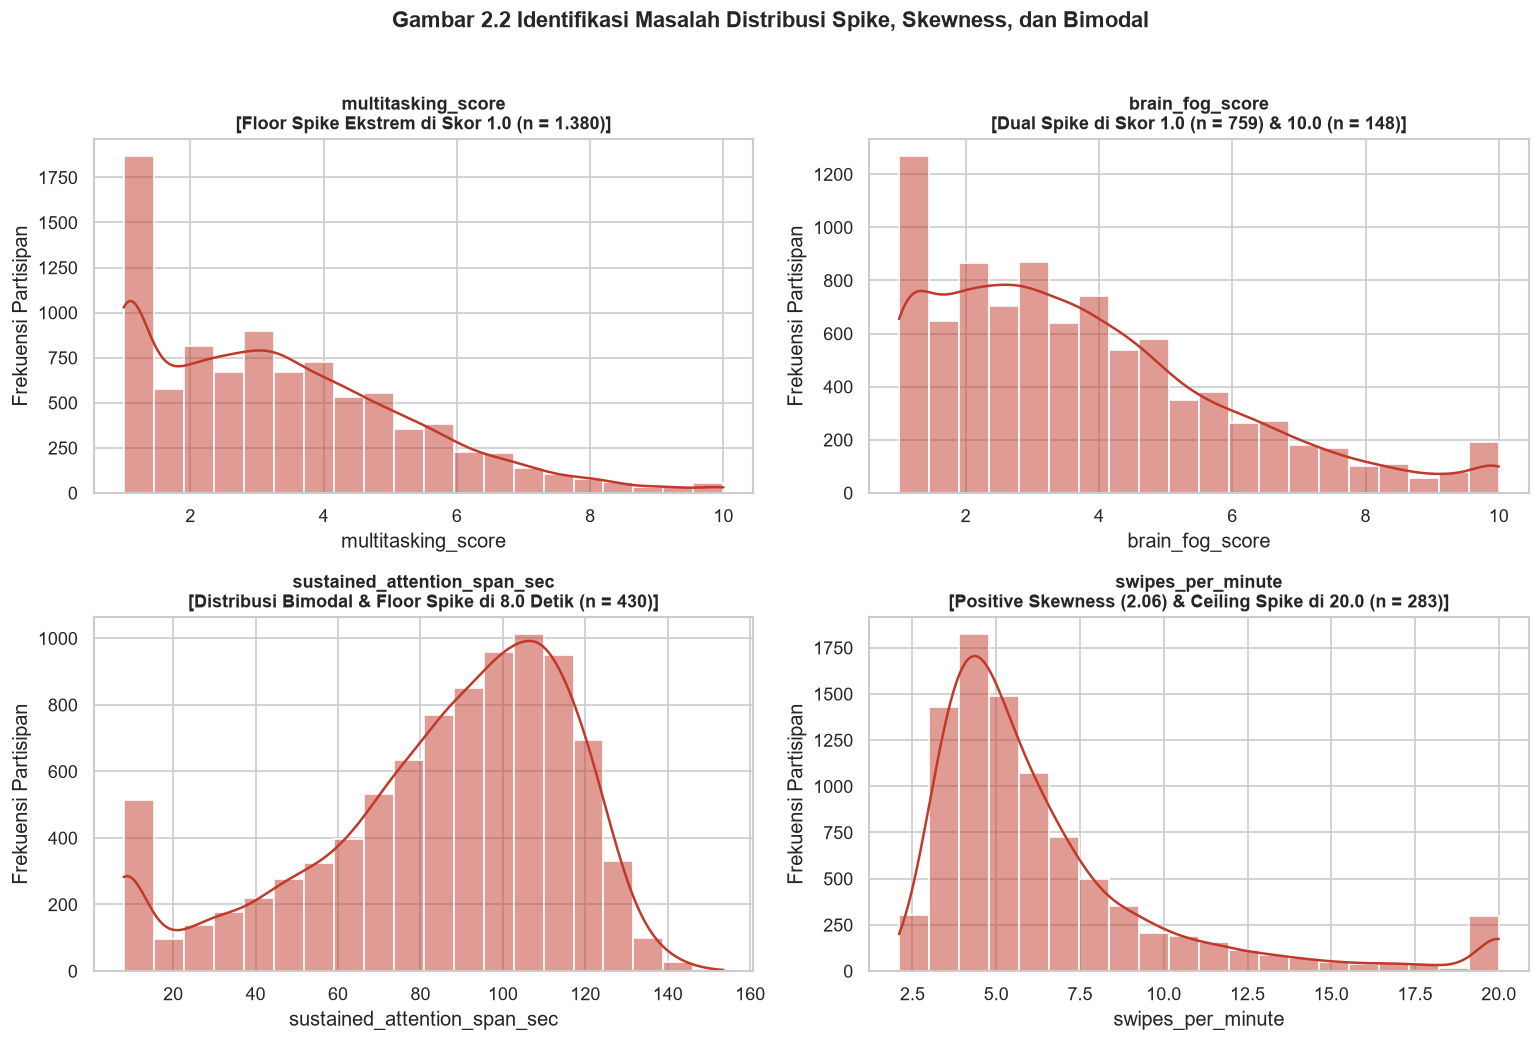

In [ ]:
# Visualisasi 2: Histogram & KDE untuk Bukti Distribusi Spike dan Bimodal
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
spike_vars = [
    ('multitasking_score', 'Floor Spike Ekstrem di Skor 1.0 (n = 1.380)'),
    ('brain_fog_score', 'Dual Spike di Skor 1.0 (n = 759) & 10.0 (n = 148)'),
    ('sustained_attention_span_sec', 'Distribusi Bimodal & Floor Spike di 8.0 Detik (n = 430)'),
    ('swipes_per_minute', 'Positive Skewness (2.06) & Ceiling Spike di 20.0 (n = 283)')
]

for ax, (col, desc) in zip(axes.flatten(), spike_vars):
    sns.histplot(df[col], bins=20, kde=True, ax=ax, color='#c0392b')
    ax.set_title(f'{col}\n[{desc}]', fontsize=10.5, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frekuensi Partisipan')

plt.suptitle('Gambar 2.2 Identifikasi Masalah Distribusi Spike, Skewness, dan Bimodal', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

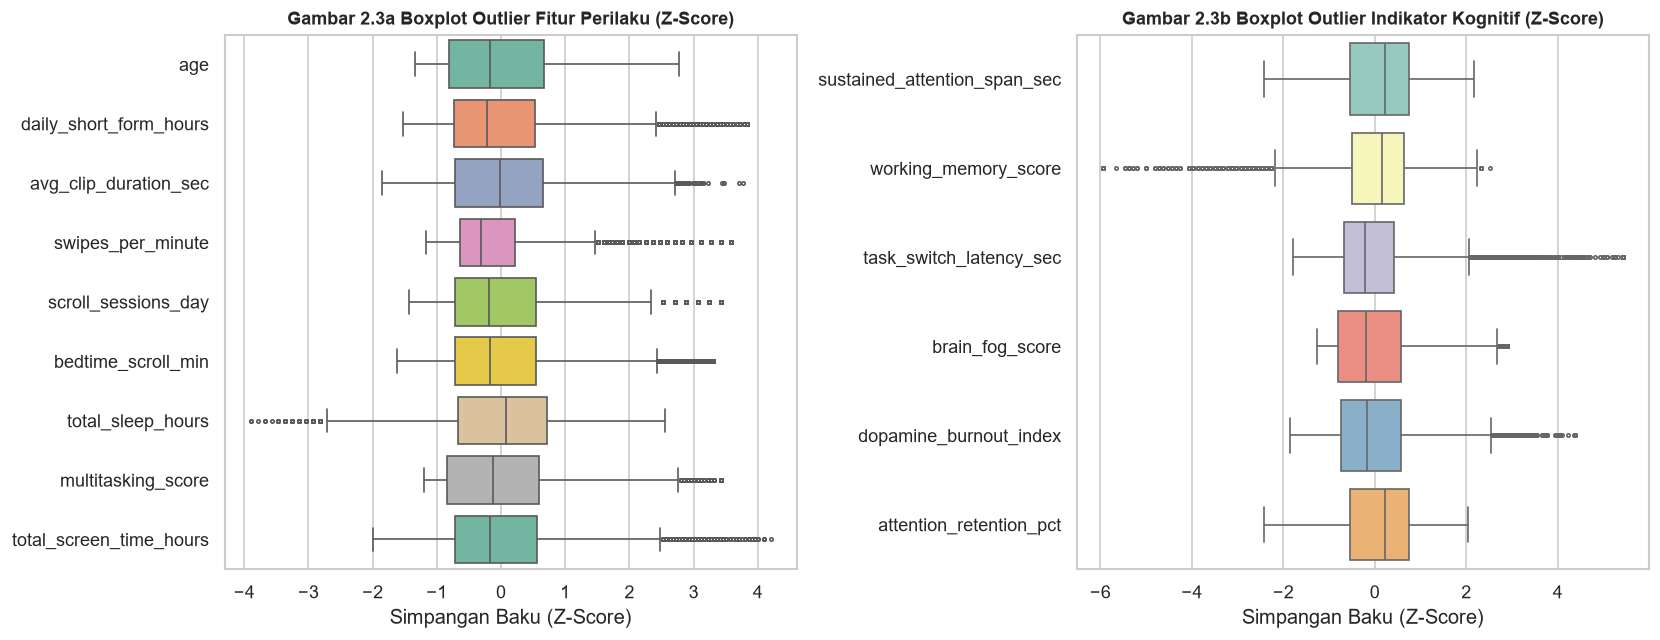

In [ ]:
# Visualisasi 3: Boxplot Sebaran Outlier (Distandarisasi Z-Score)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

behav_z = (df[behavioral_num_cols] - df[behavioral_num_cols].mean()) / df[behavioral_num_cols].std()
sns.boxplot(data=behav_z, orient='h', ax=axes[0], palette='Set2', fliersize=2)
axes[0].set_title('Gambar 2.3a Boxplot Outlier Fitur Perilaku (Z-Score)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Simpangan Baku (Z-Score)')

cog_z = (df[cognitive_num_cols] - df[cognitive_num_cols].mean()) / df[cognitive_num_cols].std()
sns.boxplot(data=cog_z, orient='h', ax=axes[1], palette='Set3', fliersize=2)
axes[1].set_title('Gambar 2.3b Boxplot Outlier Indikator Kognitif (Z-Score)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Simpangan Baku (Z-Score)')

plt.tight_layout()
plt.show()

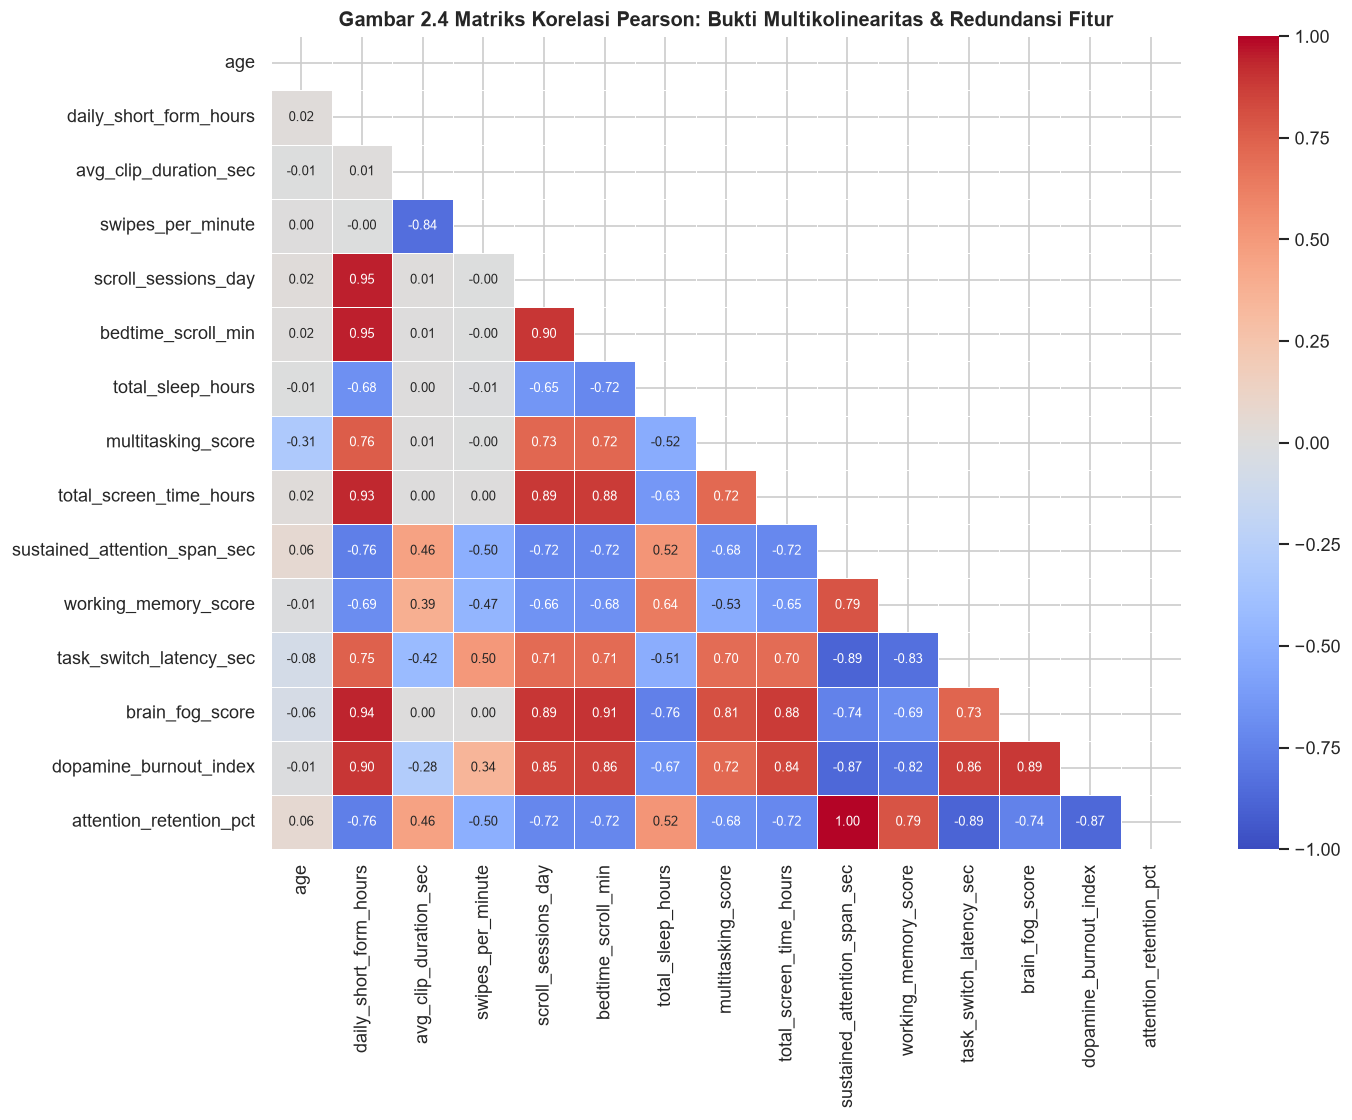

In [ ]:
# Visualisasi 4: Heatmap Korelasi Pearson (Bukti Multikolinearitas & Redundansi r = 1.00)
plt.figure(figsize=(12, 9.5))
corr_mat = df[all_num_cols].corr()
upper_mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(corr_mat, mask=upper_mask, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, linewidths=0.5, annot_kws={"size": 8})
plt.title('Gambar 2.4 Matriks Korelasi Pearson: Bukti Multikolinearitas & Redundansi Fitur', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [5]:
import os

# 1. Buat folder 'artifacts' jika belum ada
os.makedirs('artifacts', exist_ok=True)

In [7]:
# 2. Load Dataset Mentah
DATA_PATH = 'dataset/short_form_brain_rot_cognitive_decay.csv'
if not os.path.exists(DATA_PATH):
    DATA_PATH = 'short_form_brain_rot_cognitive_decay.csv'

df = pd.read_csv(DATA_PATH)
print(f"Dataset berhasil dimuat: {df.shape[0]} baris x {df.shape[1]} kolom\n")

Dataset berhasil dimuat: 9000 baris x 19 kolom



In [8]:
# ==============================================================================
# TABEL 2.1: STRUKTUR ATRIBUT, TIPE DATA, MISSING VALUES & PERAN VARIABEL
# ==============================================================================
peran_map = {
    'participant_id': 'Identitas Unik Partisipan (Dibuang di Bab 3)',
    'age': 'Fitur Prediktor Demografi (X1)',
    'gender': 'Fitur Prediktor Demografi (X2)',
    'primary_platform': 'Fitur Prediktor Platform (X3)',
    'daily_short_form_hours': 'Fitur Prediktor Perilaku Layar (X4)',
    'avg_clip_duration_sec': 'Fitur Prediktor Perilaku Layar (X5)',
    'swipes_per_minute': 'Fitur Prediktor Perilaku Layar (X6)',
    'scroll_sessions_day': 'Fitur Prediktor Perilaku Layar (X7)',
    'bedtime_scroll_min': 'Fitur Prediktor Perilaku Tidur (X8)',
    'total_sleep_hours': 'Fitur Prediktor Perilaku Tidur (X9)',
    'multitasking_score': 'Fitur Prediktor Perilaku Kognitif (X10)',
    'total_screen_time_hours': 'Fitur Prediktor Perilaku Layar (X11)',
    'sustained_attention_span_sec': 'Skor Klinis Kognitif (Target Leakage - Dibuang)',
    'working_memory_score': 'Skor Klinis Kognitif (Target Leakage - Dibuang)',
    'task_switch_latency_sec': 'Skor Klinis Kognitif (Target Leakage - Dibuang)',
    'brain_fog_score': 'Skor Klinis Kognitif (Target Leakage - Dibuang)',
    'dopamine_burnout_index': 'Skor Klinis Kognitif (Target Leakage - Dibuang)',
    'attention_retention_pct': 'Skor Klinis Kognitif (Multikolinearitas r=1.0 - Dibuang)',
    'cognitive_decay_tier': 'Variabel Target Klasifikasi (y)'
}

tabel_2_1 = pd.DataFrame({
    'No': range(1, len(df.columns) + 1),
    'Nama Atribut': df.columns,
    'Tipe Data': df.dtypes.astype(str).values,
    'Non-Null': df.notnull().sum().values,
    'Missing': df.isnull().sum().values,
    'Unik': df.nunique().values,
    'Peran Variabel': [peran_map[col] for col in df.columns]
})
tabel_2_1.to_csv('artifacts/Tabel_2_1_Struktur_Atribut.csv', index=False)
print("=== TABEL 2.1 ===")
print(tabel_2_1.to_string(index=False))


=== TABEL 2.1 ===
 No                 Nama Atribut Tipe Data  Non-Null  Missing  Unik                                           Peran Variabel
  1               participant_id       str      9000        0  9000             Identitas Unik Partisipan (Dibuang di Bab 3)
  2                          age     int64      9000        0    40                           Fitur Prediktor Demografi (X1)
  3                       gender       str      9000        0     3                           Fitur Prediktor Demografi (X2)
  4             primary_platform       str      9000        0     4                            Fitur Prediktor Platform (X3)
  5       daily_short_form_hours   float64      9000        0   103                      Fitur Prediktor Perilaku Layar (X4)
  6        avg_clip_duration_sec   float64      9000        0   227                      Fitur Prediktor Perilaku Layar (X5)
  7            swipes_per_minute   float64      9000        0   105                      Fitur Prediktor Pe

In [9]:
# ==============================================================================
# TABEL 2.2: STATISTIK DESKRIPTIF, SKEWNESS & OUTLIER (9 FITUR NUMERIK PERILAKU)
# ==============================================================================
behav_num = [
    'age', 'daily_short_form_hours', 'avg_clip_duration_sec', 
    'swipes_per_minute', 'scroll_sessions_day', 'bedtime_scroll_min', 
    'total_sleep_hours', 'multitasking_score', 'total_screen_time_hours'
]

desc = df[behav_num].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(2)
desc.columns = ['Mean', 'Std.Dev', 'Min', 'Q1 (25%)', 'Median (50%)', 'Q3 (75%)', 'Max']
desc['Skewness'] = df[behav_num].skew().round(2)

outlier_counts, outlier_pcts = [], []
for col in behav_num:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    out = ((df[col] < (q1 - 1.5 * iqr)) | (df[col] > (q3 + 1.5 * iqr))).sum()
    outlier_counts.append(out)
    outlier_pcts.append(round(out / len(df) * 100, 2))

desc['Outlier (Baris)'] = outlier_counts
desc['Outlier (%)'] = outlier_pcts
tabel_2_2 = desc.reset_index().rename(columns={'index': 'Nama Fitur'})
tabel_2_2.to_csv('artifacts/Tabel_2_2_Statistik_Numerik_Outlier.csv', index=False)
print("\n=== TABEL 2.2 ===")
print(tabel_2_2.to_string(index=False))


=== TABEL 2.2 ===
             Nama Fitur  Mean  Std.Dev  Min  Q1 (25%)  Median (50%)  Q3 (75%)   Max  Skewness  Outlier (Baris)  Outlier (%)
                    age 28.70     9.50 16.0      21.0          27.0      35.0  55.0      0.76                0         0.00
 daily_short_form_hours  3.20     1.91  0.3       1.8           2.8       4.2  10.5      1.09              244         2.71
  avg_clip_duration_sec 11.50     4.58  3.0       8.2          11.4      14.5  28.8      0.24               41         0.46
      swipes_per_minute  6.48     3.77  2.1       4.1           5.3       7.3  20.0      2.06              726         8.07
    scroll_sessions_day  9.00     5.55  1.0       5.0           8.0      12.0  28.0      0.94              242         2.69
     bedtime_scroll_min 59.22    36.63  0.0      33.0          53.0      79.0 180.0      0.90              237         2.63
      total_sleep_hours  7.13     0.93  3.5       6.5           7.2       7.8   9.5     -0.36               79   

In [10]:
# ==============================================================================
# TABEL 2.3: ANALISIS KORELASI 6 FITUR SKOR KOGNITIF (BUKTI TARGET LEAKAGE)
# ==============================================================================
cog_num = [
    'sustained_attention_span_sec', 'working_memory_score', 
    'task_switch_latency_sec', 'brain_fog_score', 
    'dopamine_burnout_index', 'attention_retention_pct'
]
desc_cog = df[cog_num].describe().T[['mean', 'std', 'min', '50%', 'max']].round(2)
desc_cog.columns = ['Mean', 'Std.Dev', 'Min', 'Median (50%)', 'Max']
desc_cog['Korelasi dgn dopamine_burnout'] = [round(df[c].corr(df['dopamine_burnout_index']), 4) for c in cog_num]
desc_cog['Korelasi dgn sustained_attention'] = [round(df[c].corr(df['sustained_attention_span_sec']), 4) for c in cog_num]
desc_cog['Status di Bab 3'] = [
    'Dihapus (Target Leakage)',
    'Dihapus (Target Leakage)',
    'Dihapus (Target Leakage)',
    'Dihapus (Target Leakage)',
    'Dihapus (Target Leakage)',
    'Dihapus (Multikolinearitas r=1.0000 & Leakage)'
]
tabel_2_3 = desc_cog.reset_index().rename(columns={'index': 'Fitur Skor Kognitif'})
tabel_2_3.to_csv('artifacts/Tabel_2_3_Analisis_Korelasi_Leakage.csv', index=False)
print("\n=== TABEL 2.3 ===")
print(tabel_2_3.to_string(index=False))


=== TABEL 2.3 ===
         Fitur Skor Kognitif  Mean  Std.Dev  Min  Median (50%)   Max  Korelasi dgn dopamine_burnout  Korelasi dgn sustained_attention                                Status di Bab 3
sustained_attention_span_sec 84.86    31.79  8.0          91.7 153.5                        -0.8700                            1.0000                       Dihapus (Target Leakage)
        working_memory_score  7.32     1.06  1.0           7.5  10.0                        -0.8194                            0.7902                       Dihapus (Target Leakage)
     task_switch_latency_sec  9.41     4.17  2.0           8.5  32.0                         0.8609                           -0.8890                       Dihapus (Target Leakage)
             brain_fog_score  3.74     2.16  1.0           3.3  10.0                         0.8890                           -0.7433                       Dihapus (Target Leakage)
      dopamine_burnout_index 32.95    15.01  5.0          30.5  98.5        

In [11]:
# ==============================================================================
# TABEL 2.4: DISTRIBUSI KELAS TARGET (cognitive_decay_tier)
# ==============================================================================
order_tiers = [
    'Normal / Intact Focus',
    'Mild Attentional Strain',
    'Severe Focus Fragmentation',
    'Acute Brain Rot / Executive Burnout'
]
vc = df['cognitive_decay_tier'].value_counts().reindex(order_tiers)
vc_pct = (df['cognitive_decay_tier'].value_counts(normalize=True).reindex(order_tiers) * 100).round(2)

tabel_2_4 = pd.DataFrame({
    'Kode Tier': ['Tier 0 (Sehat)', 'Tier 1 (Ringan)', 'Tier 2 (Parah)', 'Tier 3 (Kritis)'],
    'Kelas Target (cognitive_decay_tier)': order_tiers,
    'Jumlah Partisipan': vc.values,
    'Persentase (%)': vc_pct.values,
    'Status Proporsi': ['Mayoritas Dominan', 'Mayoritas', 'Minoritas Menengah', 'Minoritas Ekstrem (Imbalance)']
})
tabel_2_4.to_csv('artifacts/Tabel_2_4_Distribusi_Target.csv', index=False)
print("\n=== TABEL 2.4 ===")
print(tabel_2_4.to_string(index=False))


=== TABEL 2.4 ===
      Kode Tier Kelas Target (cognitive_decay_tier)  Jumlah Partisipan  Persentase (%)               Status Proporsi
 Tier 0 (Sehat)               Normal / Intact Focus               3863           42.92             Mayoritas Dominan
Tier 1 (Ringan)             Mild Attentional Strain               3677           40.86                     Mayoritas
 Tier 2 (Parah)          Severe Focus Fragmentation               1355           15.06            Minoritas Menengah
Tier 3 (Kritis) Acute Brain Rot / Executive Burnout                105            1.17 Minoritas Ekstrem (Imbalance)


In [12]:
# ==============================================================================
# TABEL 2.5: DISTRIBUSI FITUR KATEGORIKAL (gender & primary_platform)
# ==============================================================================
cat_rows = []
for col in ['gender', 'primary_platform']:
    counts = df[col].value_counts()
    pcts = (df[col].value_counts(normalize=True) * 100).round(2)
    for k in counts.index:
        cat_rows.append({
            'Nama Fitur': col,
            'Kategori': k,
            'Jumlah Partisipan': counts[k],
            'Persentase (%)': pcts[k]
        })
tabel_2_5 = pd.DataFrame(cat_rows)
tabel_2_5.to_csv('artifacts/Tabel_2_5_Distribusi_Kategorikal.csv', index=False)
print("\n=== TABEL 2.5 ===")
print(tabel_2_5.to_string(index=False))


=== TABEL 2.5 ===
      Nama Fitur           Kategori  Jumlah Partisipan  Persentase (%)
          gender               Male               4395           48.83
          gender             Female               4338           48.20
          gender         Non-Binary                267            2.97
primary_platform             TikTok               3684           40.93
primary_platform    Instagram Reels               3044           33.82
primary_platform     YouTube Shorts               1609           17.88
primary_platform Snapchat Spotlight                663            7.37


In [13]:
# ==============================================================================
# SIMPAN GAMBAR 2.1, GAMBAR 2.2, DAN GAMBAR 2.3 KE FOLDER artifacts/
# ==============================================================================
# Gambar 2.1: Bar Chart Distribusi Kelas Target
colors = ['#2b5c8f', '#3690c0', '#f68e5f', '#d9383a']
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)
bars = ax.barh(order_tiers, vc.values, color=colors, edgecolor='black', height=0.6)
ax.invert_yaxis()
ax.set_xlabel('Jumlah Partisipan (Orang)', fontsize=10, fontweight='bold')
ax.set_title('Distribusi Ketimpangan Kelas Target (cognitive_decay_tier)', fontsize=11, fontweight='bold', pad=12)
ax.set_xlim(0, 4500)
for bar, c in zip(bars, vc.values):
    pct = c / len(df) * 100
    ax.text(bar.get_width() + 60, bar.get_y() + bar.get_height()/2, f'{c} ({pct:.2f}%)', 
            va='center', ha='left', fontsize=9, fontweight='bold')
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('artifacts/Gambar_2_1_Distribusi_Target.png')
plt.close()

# Gambar 2.2: Boxplot Outlier 9 Fitur Perilaku
fig, axes = plt.subplots(3, 3, figsize=(12, 8), dpi=150)
axes = axes.flatten()
for i, col in enumerate(behav_num):
    sns.boxplot(x=df[col], ax=axes[i], color='#6baed6', fliersize=3)
    axes[i].set_title(f'{col} (Skew: {df[col].skew():.2f})', fontsize=9, fontweight='bold')
    axes[i].set_xlabel('')
plt.suptitle('Deteksi Outlier dan Skewness pada 9 Fitur Perilaku Numerik', fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('artifacts/Gambar_2_2_Boxplot_Outliers.png', bbox_inches='tight')
plt.close()

# Gambar 2.3: Heatmap Korelasi Pearson
num_all = df.select_dtypes(include=[np.number]).columns
fig, ax = plt.subplots(figsize=(11, 8.5), dpi=150)
sns.heatmap(df[num_all].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax, annot_kws={'size': 7})
ax.set_title('Matriks Korelasi Pearson Seluruh Variabel Numerik', fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('artifacts/Gambar_2_3_Heatmap_Korelasi.png')
plt.close()